<a href="https://colab.research.google.com/github/cw1079/ML_Course26/blob/main/HW4/heart_disease_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Connor Williams**

In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve,
    RocCurveDisplay,
    ConfusionMatrixDisplay
)


**Task 1: Load the dataset into Pandas DataFrame**


In [19]:
#pip install ucimlrepo
from ucimlrepo import fetch_ucirepo

# fetch dataset
heart_disease = fetch_ucirepo(id=45)

# data (as pandas dataframes)
X = heart_disease.data.features
y = heart_disease.data.targets

# metadata
print(heart_disease.metadata)

# variable information
print(heart_disease.variables)

#Creating data frame
df = pd.concat([X, y], axis=1)
df = df.rename(columns={'num': 'target'})




{'uci_id': 45, 'name': 'Heart Disease', 'repository_url': 'https://archive.ics.uci.edu/dataset/45/heart+disease', 'data_url': 'https://archive.ics.uci.edu/static/public/45/data.csv', 'abstract': '4 databases: Cleveland, Hungary, Switzerland, and the VA Long Beach', 'area': 'Health and Medicine', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 303, 'num_features': 13, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': ['Age', 'Sex'], 'target_col': ['num'], 'index_col': None, 'has_missing_values': 'yes', 'missing_values_symbol': 'NaN', 'year_of_dataset_creation': 1989, 'last_updated': 'Fri Nov 03 2023', 'dataset_doi': '10.24432/C52P4X', 'creators': ['Andras Janosi', 'William Steinbrunn', 'Matthias Pfisterer', 'Robert Detrano'], 'intro_paper': {'ID': 231, 'type': 'NATIVE', 'title': 'International application of a new probability algorithm for the diagnosis of coronary artery disease.', 'authors': 'R. Detrano, A. Jánosi, W. Steinbrunn, M

Task 2: Using structural inspection methods
---
I will use head() to display the first five rows, info() to check the data types and missing values and also describe() to see things like the mean, minimum and max values. This also looks at the categorical features.

In [23]:
display(df.head())

df.info()

display(df.describe())
#categorial
cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang',
            'slope', 'ca', 'thal']

display(df[cat_cols].describe())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  target    303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000,303.000000
mean,54.438944,0.679868,3.158416,131.689769,246.693069,0.148515,0.990099,149.607261,0.326733,1.039604,1.600660,0.672241,4.734219,0.937294
std,9.038662,0.467299,0.960126,17.599748,51.776918,0.356198,0.994971,22.875003,0.469794,1.161075,0.616226,0.937438,1.939706,1.228536
min,29.000000,0.000000,1.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
25%,48.000000,0.000000,3.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,3.000000,0.000000
50%,56.000000,1.000000,3.000000,130.000000,241.000000,0.000000,1.000000,153.000000,0.000000,0.800000,2.000000,0.000000,3.000000,0.000000
75%,61.000000,1.000000,4.000000,140.000000,275.000000,0.000000,2.000000,166.000000,1.000000,1.600000,2.000000,1.000000,7.000000,2.000000
max,77.000000,1.000000,4.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,3.000000,3.000000,7.000000,4.000000


,sex,cp,fbs,restecg,exang,slope,ca,thal
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,299.000000,301.000000
mean,0.679868,3.158416,0.148515,0.990099,0.326733,1.600660,0.672241,4.734219
std,0.467299,0.960126,0.356198,0.994971,0.469794,0.616226,0.937438,1.939706
min,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,3.000000
25%,0.000000,3.000000,0.000000,0.000000,0.000000,1.000000,0.000000,3.000000
50%,1.000000,3.000000,0.000000,1.000000,0.000000,2.000000,0.000000,3.000000
75%,1.000000,4.000000,0.000000,2.000000,1.000000,2.000000,1.000000,7.000000
max,1.000000,4.000000,1.000000,2.000000,1.000000,3.000000,3.000000,7.000000


Task 3: Quantify and Handle Missing or Implicit Values
---
This code checks the dataset for missing values including the hidden values represented by ?. These values are replaced with NaN so Pandas can recognize them. The code then counts the missing values in each column and creates two SimpleImputer objects. The numerical features use the median while the categorical  use the most frequent value.


In [11]:

df = df.replace('?', np.nan)

print("Missing values:")
print(df.isnull().sum())

num_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

cat_cols = ['sex', 'cp', 'fbs', 'restecg', 'exang',
            'slope', 'ca', 'thal']

num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

print("\nImputers created successfully")


Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Imputers created successfully


### Task 4: Creating ColumnTransformer and Pipeline

This creates a preprocessing pipeline to prepare the dataset for learning. Numerical features are filled using the median and scaled with StandardScaler. Categorical features are filled using the most frequent value using OneHotEncoder. A ColumnTransformer combines both processes. The dataset is separated into features and split into 80% training data and 20% testing data.

In [20]:

# Numerical
num_pipeline = Pipeline([
    ('imputer', num_imputer),
    ('scaler', StandardScaler())
])

# Categorical
cat_pipeline = Pipeline([
    ('imputer', cat_imputer),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combining
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

X = df.drop(columns='target')
y = (df['target'] > 0).astype(int)

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training:", len(X_train))
print("Testing:", len(X_test))


Training: 242
Testing: 61


### Task 5: Training a Support Vector Classifier

This trains a Support Vector Classifier using an RBF kernel to predict whether a patient has heart disease. The model uses the pipeline and probability predictions. Its evaluated using a confusion matrix, classification report and ROC-AUC score. The confusion matrix shows the predictions and if they are correct or not while the ROC curve shows how well the model separates patients with or without heart disease.

Confusion Matrix:
[[28  5]
 [ 2 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

ROC-AUC: 0.9642857142857143


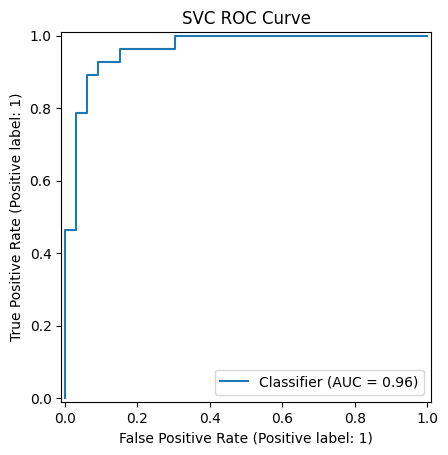

In [14]:

svc_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', SVC(kernel='rbf', probability=True, random_state=42))
])

svc_pipeline.fit(X_train, y_train)

svc_pred = svc_pipeline.predict(X_test)
svc_prob = svc_pipeline.predict_proba(X_test)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, svc_pred))

print("\nClassification Report:")
print(classification_report(y_test, svc_pred))

print("ROC-AUC:", roc_auc_score(y_test, svc_prob))

RocCurveDisplay.from_predictions(y_test, svc_prob)
plt.title("SVC ROC Curve")
plt.show()


### Task 6: Training a Decision Tree Classifier

This code trains a Decision Tree Classifier using the same training and testing data as the SVC model. It evaluates the Decision Tree using a confusion matrix, classification report, and ROC-AUC curve. The results are then compared with the SVC model to determine which performs better at predicting heart disease.

SVC
Confusion Matrix:
[[28  5]
 [ 2 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61

ROC-AUC: 0.964


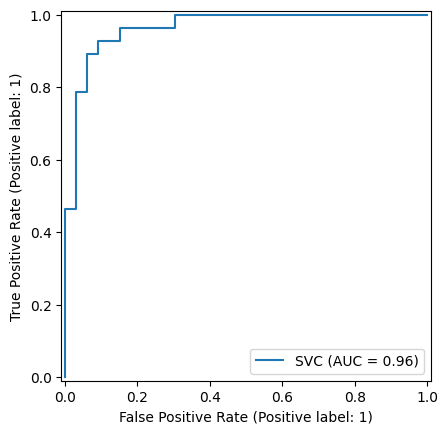

Decision Tree
Confusion Matrix:
[[22 11]
 [ 5 23]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.67      0.73        33
           1       0.68      0.82      0.74        28

    accuracy                           0.74        61
   macro avg       0.75      0.74      0.74        61
weighted avg       0.75      0.74      0.74        61

ROC-AUC: 0.744


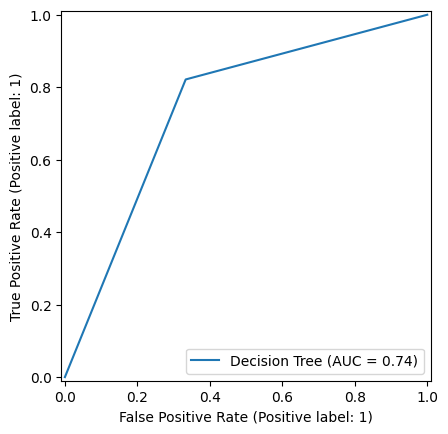


Model Comparison:
SVC ROC-AUC: 0.964
Decision Tree ROC-AUC: 0.744


In [21]:

# Create and train Decision Tree
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

tree_pipeline.fit(X_train, y_train)

def evaluate_model(model, name):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    print(name)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))
    print("\nClassification Report:")
    print(classification_report(y_test, predictions))

    auc = roc_auc_score(y_test, probabilities)
    print("ROC-AUC:", round(auc, 3))

    RocCurveDisplay.from_predictions(
        y_test, probabilities, name=name
    )
    plt.show()

    return auc

# Evaluate and compare both models
svc_auc = evaluate_model(svc_pipeline, "SVC")
tree_auc = evaluate_model(tree_pipeline, "Decision Tree")

print("\nModel Comparison:")
print("SVC ROC-AUC:", round(svc_auc, 3))
print("Decision Tree ROC-AUC:", round(tree_auc, 3))


### Task 7: Hyperparameter Tuning

This code uses GridSearchCV to test different values of C and gamma for the SVC model. These parameters control how the model learns patterns and creates decision boundaries. Cross-validation is used to compare the settings and select the combination with the best average ROC-AUC score. The tuned model is then evaluated using the testing data.

In [22]:

# testing parameters
param_grid = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__gamma': ['scale', 0.01, 0.1, 1]
}

# GridSearchCV
grid_search = GridSearchCV(
    svc_pipeline,
    param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation ROC-AUC:", grid_search.best_score_)


best_svc = grid_search.best_estimator_
tuned_auc = roc_auc_score(
    y_test, best_svc.predict_proba(X_test)[:, 1]
)

print("Tuned Test ROC-AUC:", round(tuned_auc, 3))


Best Parameters: {'classifier__C': 1, 'classifier__gamma': 0.01}
Best Cross-Validation ROC-AUC: 0.8882830535004448
Tuned Test ROC-AUC: 0.968


### Task 8: Generating a decision tree visualization

This code visualizes the trained Decision Tree using plot_tree to show how the model classifies patients based on features. It also displays feature importance scores to help identify which patient characteristics have the greatest influence on predictions..

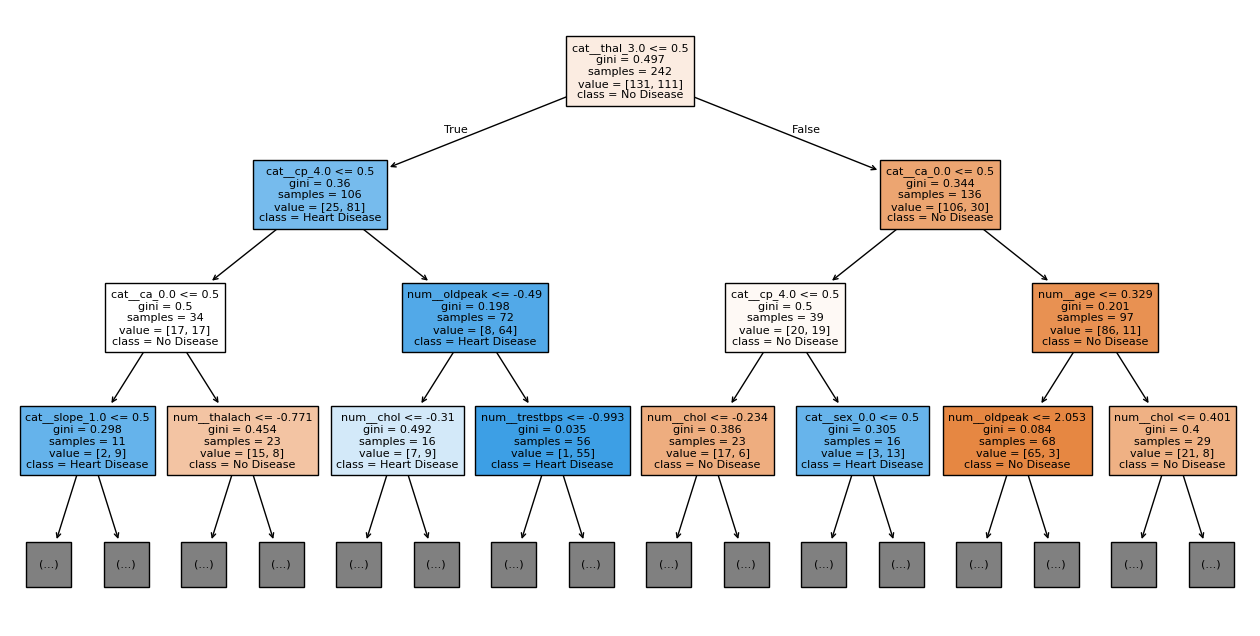

cat__thal_3.0       0.292921
cat__cp_4.0         0.119427
num__chol           0.110055
num__oldpeak        0.107935
cat__ca_0.0         0.097622
num__age            0.096128
cat__sex_0.0        0.033909
num__trestbps       0.027639
cat__cp_3.0         0.019416
num__thalach        0.018673
cat__fbs_0.0        0.016444
cat__slope_1.0      0.016138
cat__exang_1.0      0.015216
cat__ca_1.0         0.014265
cat__restecg_0.0    0.008321
cat__cp_2.0         0.005890
cat__sex_1.0        0.000000
cat__cp_1.0         0.000000
cat__restecg_2.0    0.000000
cat__fbs_1.0        0.000000
cat__slope_2.0      0.000000
cat__exang_0.0      0.000000
cat__restecg_1.0    0.000000
cat__slope_3.0      0.000000
cat__ca_2.0         0.000000
cat__ca_3.0         0.000000
cat__thal_6.0       0.000000
cat__thal_7.0       0.000000
dtype: float64


In [18]:

tree_model = tree_pipeline.named_steps['classifier']

feature_names = tree_pipeline.named_steps[
    'preprocessor'
].get_feature_names_out()

plt.figure(figsize=(16, 8))

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=['No Disease', 'Heart Disease'],
    filled=True,
    max_depth=3,
    fontsize=8
)

plt.show()

importances = pd.Series(
    tree_model.feature_importances_,
    index=feature_names
)

print(importances.sort_values(ascending=False))
